# 02 · Preparação dos Dados
Fase 3 do CRISP-DM: limpar, anonimizar e transformar os registros em **perfis** (uma linha por pessoa).

> ⚠️ **Dados fictícios.** Enquanto a coleta real não termina, este notebook usa
> `data/processed/desejos_demo.csv`, gerado por `src/exemplo.py`: 12 pessoas inventadas a partir de
> 4 estilos de desejo (gastronômico, tech, moda, pet), mais o perfil de exemplo "você".
> **Para usar os dados reais:** baixe o CSV anonimizado no app (*Meus Desejos → Baixar CSV anonimizado*),
> salve como `data/processed/desejos.csv` e troque `ARQUIVO` na célula abaixo. O resto roda igual.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # para importar src/

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette=["#6D4AFF", "#E8701F", "#17975F", "#C13B7A", "#2A7AB8", "#8C8A9E"])
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 2)

In [2]:
ARQUIVO = Path.cwd().parent / "data" / "processed" / "desejos_demo.csv"
df = pd.read_csv(ARQUIVO, parse_dates=["criado_em"])
print(f"{len(df)} desejos de {df['usuario'].nunique()} pessoas")
df.head()

361 desejos de 13 pessoas


,usuario,criado_em,item,categoria,tipo,faixa_preco,confianca,cidade,acao
0,exemplo:ana,2026-10-17 12:04:00,macarrão,comida,receita,R$ 15–80,0.87,Vitória - ES,ver_mapa
1,exemplo:ana,2026-10-19 15:58:00,café,bebidas,receita,R$ 5–60,0.42,Vitória - ES,ver_mapa
2,exemplo:ana,2026-10-19 20:55:00,arroz e feijão,comida,receita,R$ 15–80,0.80,Vitória - ES,ver_loja_online
3,exemplo:ana,2026-10-20 09:43:00,café,bebidas,receita,R$ 5–60,0.82,Vitória - ES,ver_receita
4,exemplo:ana,2026-10-20 10:45:00,café,bebidas,receita,R$ 5–60,0.49,Vitória - ES,salvou


## 1. Limpeza
Regras:
1. Remover desejos com **confiança < 0,45**: o modelo provavelmente errou o item.
   Desejos confirmados manualmente no app (confiança vazia) são mantidos.
2. Remover **duplicados** (mesma pessoa, mesmo item, mesmo minuto).
3. Manter só pessoas com **pelo menos 10 desejos**: menos que isso não forma um perfil confiável.

In [3]:
antes = len(df)
baixa = df["confianca"].notna() & (df["confianca"] < 0.45)
df = df[~baixa]
df = df.drop_duplicates(subset=["usuario", "item", "criado_em"])
contagem = df["usuario"].value_counts()
df = df[df["usuario"].isin(contagem[contagem >= 10].index)]
print(f"{antes} → {len(df)} desejos ({baixa.sum()} removidos por baixa confiança)")

361 → 328 desejos (33 removidos por baixa confiança)


## 2. Anonimização (LGPD)
`src/exportar.anonimizar` troca o nome por um código, remove ids e fotos, arredonda a hora e deixa só a cidade.

In [4]:
from src.exportar import anonimizar
anon = anonimizar(df)
print("Colunas:", list(anon.columns))
anon.head()

Colunas: ['usuario', 'criado_em', 'item', 'categoria', 'tipo', 'faixa_preco', 'confianca', 'cidade', 'acao']


,usuario,criado_em,item,categoria,tipo,faixa_preco,confianca,cidade,acao
0,u01,2026-10-17 12:00:00,macarrão,comida,receita,R$ 15–80,0.87,Vitória - ES,ver_mapa
1,u01,2026-10-19 20:00:00,arroz e feijão,comida,receita,R$ 15–80,0.80,Vitória - ES,ver_loja_online
2,u01,2026-10-20 09:00:00,café,bebidas,receita,R$ 5–60,0.82,Vitória - ES,ver_receita
3,u01,2026-10-20 10:00:00,café,bebidas,receita,R$ 5–60,0.49,Vitória - ES,salvou
4,u01,2026-10-20 13:00:00,arroz e feijão,comida,receita,R$ 15–80,0.81,Vitória - ES,salvou


## 3. Construção do perfil de cada pessoa
Cada pessoa vira um **vetor** com a proporção dos seus desejos em cada categoria (cada linha soma 1).
É a mesma representação usada no app para comparar pessoas (`src/perfil.py`).
Usar proporção, e não contagem, evita que quem usa mais o app pareça "diferente" só por ter mais fotos.

In [5]:
from src.clustering import matriz_perfis
perfis = matriz_perfis(anon)
perfis.round(2)

categoria,animais,bebidas,beleza,brinquedos e games,calçados,casa e decoração,comida,eletrônicos,esporte e lazer,livros e papelaria,vestuário,veículos
u01,0.00,0.29,0.00,0.00,0.14,0.10,0.43,0.00,0.00,0.00,0.00,0.05
u02,0.00,0.17,0.00,0.00,0.00,0.04,0.65,0.00,0.00,0.00,0.00,0.13
u03,0.00,0.00,0.00,0.35,0.00,0.00,0.00,0.42,0.16,0.00,0.06,0.00
u04,0.00,0.25,0.00,0.00,0.00,0.08,0.46,0.00,0.00,0.00,0.04,0.17
u05,0.00,0.00,0.26,0.00,0.37,0.00,0.00,0.00,0.07,0.00,0.30,0.00
u06,0.55,0.00,0.00,0.00,0.00,0.00,0.14,0.09,0.18,0.05,0.00,0.00
u07,0.13,0.00,0.00,0.22,0.00,0.00,0.00,0.57,0.09,0.00,0.00,0.00
u08,0.00,0.00,0.18,0.43,0.00,0.00,0.00,0.21,0.07,0.00,0.11,0.00
u09,0.15,0.00,0.00,0.00,0.00,0.00,0.42,0.38,0.00,0.00,0.04,0.00
u10,0.00,0.00,0.25,0.00,0.29,0.00,0.00,0.00,0.00,0.04,0.36,0.07


Text(127.56944444444443, 0.5, '')

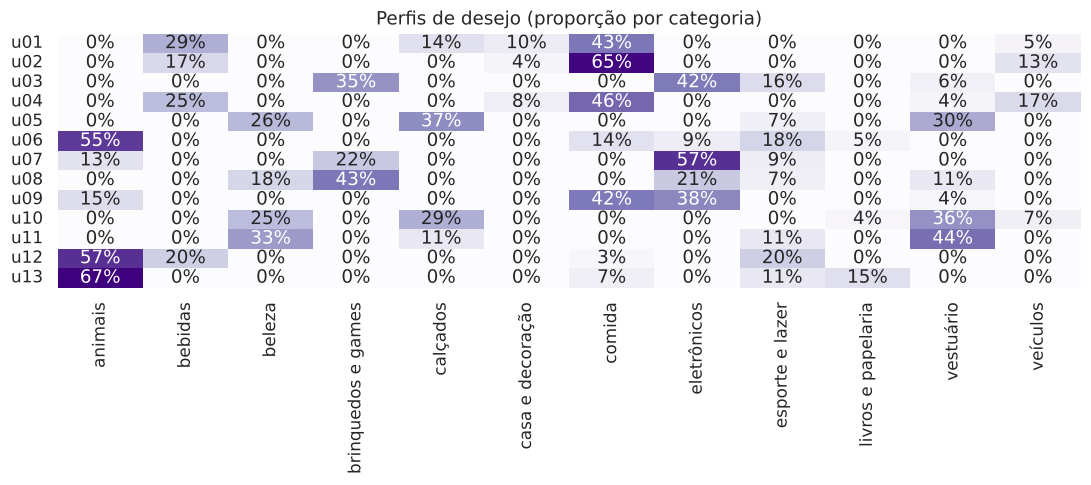

In [6]:
plt.figure(figsize=(12, 3))
sns.heatmap(perfis.loc[:, perfis.sum() > 0], annot=True, fmt=".0%", cmap="Purples", cbar=False)
plt.title("Perfis de desejo (proporção por categoria)"); plt.xlabel(""); plt.ylabel("")

In [7]:
saida = Path.cwd().parent / "data" / "processed" / "perfis_demo.csv"
perfis.to_csv(saida, index_label="usuario")
print("Salvo em", saida.relative_to(Path.cwd().parent))

Salvo em data/processed/perfis_demo.csv
